# Chapter 18 | Worked solutions

*Language Understanding*

These twelve solutions follow the chapter's order: reason about representations,
pooling and entity counts, verify the helpers, then design evaluations. The
written PDF contains every explanation and both plots. The notebook PDF also
contains the executed code and outputs.

The examples use small supplied arrays and annotations on a CPU. They do not
download or train an encoder. This isolates the heads and evaluation rules from
the model that would produce the features. In particular, padding invariance below
holds for fixed features; it cannot establish that an encoder's attention mask is
correct. Span boundaries are zero-based and half-open; tags use IOB2.

Open this notebook inside a copy of `transformers-book`, install the
repository requirements and Matplotlib, and run all cells in order. The setup
records the package versions used for the saved results.

In [1]:
from pathlib import Path
import sys

import numpy as np

working_directory = Path.cwd()
for repo_root in (working_directory, *working_directory.parents):
    model_path = (
        repo_root / "examples" / "ch18_understanding"
    )
    if model_path.is_dir():
        sys.path.insert(0, str(repo_root))
        break
else:
    raise FileNotFoundError(
        "Open this notebook inside transformers-book."
    )

import platform
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from examples.ch18_understanding.model import (
    bio_spans, first_piece_labels, first_piece_predictions,
    sentence_logits, span_metrics,
)
plt.rcParams.update({"figure.figsize": (7.5, 3.4), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
print("Python", platform.python_version())
print("NumPy", np.__version__, "Matplotlib", matplotlib.__version__)
print("CPU; supplied arrays; no model download or training")

Python 3.12.14
NumPy 2.5.4 Matplotlib 3.11.2
CPU; supplied arrays; no model download or training


## 1. Find what word counts lose

Choose vocabulary order `(Ari, called, Sam)`. Both sentences have count vector
$(1,1,1)$. A classifier receiving only that vector must receive the same evidence
for both sentences, however its weights were trained.

In these simple active-voice sentences, the name before *called* is the caller and
the name after it is the recipient. A Transformer with positional information can
relate those positions to the verb. Ari's contextual representation can therefore
reflect a different role in the two sentences.

Bidirectional attention supplies access to both sides; it does not by itself label
one side as earlier. Without position information or another order-sensitive
mechanism, a standard encoder's outputs permute with its inputs, and an invariant
pooling operation cannot distinguish these two bags of tokens. The counts below
check what was lost; they do not simulate a trained contextual encoder.

In [2]:
from collections import Counter
sentences = ["Ari called Sam", "Sam called Ari"]
vocabulary = ["Ari", "called", "Sam"]
vectors = [[Counter(s.split())[w] for w in vocabulary] for s in sentences]
assert vectors == [[1, 1, 1], [1, 1, 1]]
for sentence, vector in zip(sentences, vectors):
    print(sentence, "->", vector)

Ari called Sam -> [1, 1, 1]
Sam called Ari -> [1, 1, 1]


## 2. Pool only the valid rows

The mask selects the first three rows. The fourth contributes neither a vector to
the numerator nor a row to the denominator:

$$
\mathbf h_{\rm masked}=\frac{(2,0)+(1,3)+(0,1)}{3}
=\left(1,\frac43\right),\qquad
\mathbf h_{\rm all}=\frac{(3,4)+(6,6)}{4}
=\left(\frac94,\frac52\right).
$$

Let $\mathbf m$ be the mean of $n>0$ existing rows and $\mathbf p$ an added
padding vector. Keeping the unmasked mean unchanged requires

$$
\frac{n\mathbf m+\mathbf p}{n+1}=\mathbf m
\quad\Longleftrightarrow\quad \mathbf p=\mathbf m.
$$

Thus adding one row preserves the unmasked mean only when that row equals the
old mean in every coordinate. For the three valid rows, that vector is
$(1,4/3)$. Zero padding generally does not satisfy the condition. Masked pooling
remains unchanged for any excluded row while the valid feature rows stay fixed.

In [3]:
rows = np.array([[2., 0.], [1., 3.], [0., 1.], [6., 6.]])
mask = np.array([True, True, True, False])
masked = rows[mask].mean(axis=0)
unmasked = rows.mean(axis=0)
np.testing.assert_allclose(masked, [1, 4/3])
np.testing.assert_allclose(unmasked, [9/4, 5/2])
same_mean = np.vstack([rows[:3], masked]).mean(axis=0)
np.testing.assert_allclose(same_mean, masked)
print("Masked", masked.round(6), "unmasked", unmasked)
print("Append the old mean:", same_mean.round(6))

Masked [1.       1.333333] unmasked [2.25 2.5 ]
Append the old mean: [1.       1.333333]


## 3. Assign entity tags

For *Sam left Lake City*, the word tags are `B-PER, O, B-LOC, I-LOC`.
Sam starts a one-word person entity; Lake starts the location and City continues
it. Use the illustrative split `La, ##ke`, not a claim about a particular
tokenizer's actual vocabulary. The chapter assigns IDs 0, 1, 2, 3 to
`O, B-PER, B-LOC, I-LOC`.

| Token | Word ID | Supervised tag | Target ID |
| :-- | --: | :-- | --: |
| `[CLS]` | -1 | Ignored | -100 |
| Sam | 0 | B-PER | 1 |
| left | 1 | O | 0 |
| La | 2 | B-LOC | 2 |
| `##ke` | 2 | Ignored | -100 |
| City | 3 | I-LOC | 3 |

`O` is a real class: the model should learn that *left* is outside an entity.
An ignored target supplies no direct tagging loss and is not another class.
The continuation piece remains visible to attention, so its content can help
the representation at `La`. At evaluation time, take predictions at Sam, left,
La and City to recover exactly one tag per word.

An all-piece policy would require an explicit mapping such as `B-LOC, I-LOC`
for the pieces of Lake. Copying `B-LOC` to both pieces starts two entities at
subword level. Equal loss weights for all pieces also give split words more
contributions than unsplit words.

In [4]:
teaching_word_ids = [-1, 0, 1, 2, 2, 3]
teaching_labels = [1, 0, 2, 3]
aligned = first_piece_labels(teaching_word_ids, teaching_labels)
np.testing.assert_array_equal(aligned, [-100, 1, 0, 2, -100, 3])
print("First-piece targets:", aligned.tolist())
print("Direct loss contributions:", int(np.sum(aligned != -100)))

First-piece targets: [-100, 1, 0, 2, -100, 3]
Direct loss contributions: 4


## 4. Compare tag and span accuracy

The gold spans are $(0,2,\mathrm{ORG})$ and $(3,4,\mathrm{PER})$.
The predicted spans are $(0,2,\mathrm{ORG})$ and $(3,4,\mathrm{LOC})$.
The interval $[0,2)$ includes word indices 0 and 1; its end is excluded.

Four of five tags agree, giving word accuracy $4/5=80\%$. Only the organization
matches as a complete typed span. Thus TP = 1, FP = 1 and FN = 1. The wrong
location is an unmatched prediction, and the person remains unfound. Precision,
recall and $F_1$ are all $1/2$.

Matching only boundaries would incorrectly count both spans as correct. The
single-word entity has the right location in the sentence but the wrong type.

In [5]:
gold_hand = ["B-ORG", "I-ORG", "O", "B-PER", "O"]
pred_hand = ["B-ORG", "I-ORG", "O", "B-LOC", "O"]
gold_set, pred_set = bio_spans(gold_hand), bio_spans(pred_hand)
tp = len(gold_set & pred_set)
fp, fn = len(pred_set - gold_set), len(gold_set - pred_set)
assert (tp, fp, fn) == (1, 1, 1)
print("Gold:", sorted(gold_set))
print("Predicted:", sorted(pred_set))
print("TP, FP, FN:", tp, fp, fn)
print("Scores:", span_metrics(gold_hand, pred_hand))

Gold: [(0, 2, 'ORG'), (3, 4, 'PER')]
Predicted: [(0, 2, 'ORG'), (3, 4, 'LOC')]
TP, FP, FN: 1 1 1
Scores: {'correct_spans': 1, 'gold_spans': 2, 'predicted_spans': 2, 'precision': 0.5, 'recall': 0.5, 'f1': 0.5, 'word_accuracy': 0.8}


## 5. Keep sentence identity when scoring

Sentence A contributes no match, one gold entity and no prediction. Sentence B
contributes no match, no gold entity and one prediction. Together, $M=0$,
$P=1$, $G=1$. Dataset precision, recall and $F_1$ are all zero.

The two triples share offsets and type, but refer to different text. Include the
sentence ID, as in `(A, 0, 1, PER)`, or count matches inside each sentence before
adding them. Dropping the ID makes the sets intersect and falsely gives all three
scores a value of one. Individual sentences have an undefined ratio when their
denominator is zero; the dataset totals here have nonzero denominators.

For the separate C/D dataset, C has $F_1=2/(1+1)=1$ and D has
$F_1=2/(3+3)=1/3$. Their mean is $2/3$. Micro $F_1$ first adds counts,
giving $2(1+1)/(1+3+1+3)=1/2$. The latter weights the underlying entity
counts, while the former gives each sentence equal weight. Both are calculable;
they answer different aggregation questions.

In [6]:
gold_with_ids = {("A", 0, 1, "PER")}
pred_with_ids = {("B", 0, 1, "PER")}
assert len(gold_with_ids & pred_with_ids) == 0
gold_without_ids = {x[1:] for x in gold_with_ids}
pred_without_ids = {x[1:] for x in pred_with_ids}
assert len(gold_without_ids & pred_without_ids) == 1
counts = np.array([[1, 1, 1], [1, 3, 3]])  # M, P, G
matches, predicted_count, gold_count = counts.sum(axis=0)
micro_f1 = 2*matches/(predicted_count + gold_count)
sentence_f1 = 2*counts[:, 0]/(counts[:, 1] + counts[:, 2])
np.testing.assert_allclose([micro_f1, sentence_f1.mean()], [1/2, 2/3])
print("A/B: correct F1 = 0; dropping IDs falsely gives F1 = 1")
print("C/D: micro F1", micro_f1, "mean sentence F1", sentence_f1.mean())

A/B: correct F1 = 0; dropping IDs falsely gives F1 = 1
C/D: micro F1 0.5 mean sentence F1 0.6666666666666666


## 6. Change the padding rows

The first three rows from Exercise 2 represent tokens in a
sentence. The fourth row is padding. To make a sentence prediction,
the head first pools the token features, meaning it combines them
into one vector. In masked mean pooling, `True` selects a row for the
average and `False` leaves it out of both the sum and the count.
With the Boolean mask `(True, True, True, False)`, the hand
calculation is

$$
\frac{(2,0)+(1,3)+(0,1)}{3}
= \left(1,\frac{4}{3}\right).
$$

Each logit is a raw class score. The linear head takes the dot
product of the pooled vector with one row of weights per class
and adds that class's bias. Here `np.eye(2)` gives the identity
matrix and `np.zeros(2)` gives zero biases, so the first logit is
the first pooled coordinate and the second logit is the second.
Replacing the fourth row $(6,6)$ with $(20,-10)$ leaves the same
three rows selected. We therefore expect the same pooled vector
and logits before and after the replacement.

In [7]:
from examples.ch18_understanding.model import sentence_logits

features = np.array([[2, 0], [1, 3], [0, 1], [6, 6]])
valid = np.array([True, True, True, False])
weight = np.eye(2)
bias = np.zeros(2)

changed_features = features.copy()
changed_features[-1] = [20, -10]
expected_masked = [1, 4 / 3]

for name, rows in [("Original", features),
                   ("Changed padding", changed_features)]:
    pooled, logits = sentence_logits(rows, valid, weight, bias)
    shown_pool = pooled.round(6)
    shown_logits = logits.round(6)
    print(f"{name:16} pooled {shown_pool}, logits {shown_logits}")
    np.testing.assert_allclose(pooled, expected_masked)
    np.testing.assert_allclose(logits, expected_masked)

Original         pooled [1.       1.333333], logits [1.       1.333333]
Changed padding  pooled [1.       1.333333], logits [1.       1.333333]


Marking the last row `True` makes the mask select all four rows,
so the helper now computes the ordinary unmasked mean. The sum
of the first three rows is $(3,4)$. With the original fourth row,
the mean would be $((3+6)/4,(4+6)/4)=(9/4,5/2)$. After the change,
it is

$$
\frac{(3,4)+(20,-10)}{4}
= \left(\frac{23}{4},-\frac{3}{2}\right).
$$

Both coordinates can change because the fourth row now contributes
to the sum, and the divisor is four. The identity head copies each
new mean directly into the logits.

This invariance is a statement about the supplied encoder outputs. If a
  real encoder lets valid tokens attend to padding, changing a padded input can
  change the valid output rows before pooling. A pooling mask cannot repair that
  earlier contamination. Test the encoder attention mask separately.

In [8]:
all_valid = np.ones_like(valid)
unmasked_cases = [
    ("Original", features, [9 / 4, 5 / 2]),
    ("Changed padding", changed_features, [23 / 4, -3 / 2]),
]
for name, rows, expected_mean in unmasked_cases:
    pooled, logits = sentence_logits(rows, all_valid, weight, bias)
    shown_pool = pooled.round(6)
    shown_logits = logits.round(6)
    print(f"{name:16} pooled {shown_pool}, logits {shown_logits}")
    np.testing.assert_allclose(pooled, expected_mean)
    np.testing.assert_allclose(logits, expected_mean)

Original         pooled [2.25 2.5 ], logits [2.25 2.5 ]
Changed padding  pooled [ 5.75 -1.5 ], logits [ 5.75 -1.5 ]


## 7. Align a split word

There are three annotated words and seven token positions. A word
ID tells us which word a token piece belongs to. The ID `-1`
marks a position with no word, and consecutive pieces of the same
word share its ID. In `(-1, 0, 0, 1, 2, 2, -1)`, words 0 and 2
each have two pieces. Word 1 has one piece.

With first-piece supervision, copy the label of each word to its
first piece. Give the other positions the target `-100`, the
default ignore value, so their own predictions contribute no
direct loss. At evaluation time, read the predicted class IDs at
the same first-piece positions to get one prediction per word.
The table uses zero-based token positions.

| Token position | Word ID | Training target | Prediction | Keep? |
| ---: | ---: | ---: | ---: | :--- |
| 0 | -1 | -100 | 9 | No, no word |
| 1 | 0 | 4 | 4 | Yes, first piece |
| 2 | 0 | -100 | 8 | No, continuation |
| 3 | 1 | 0 | 0 | Yes, first piece |
| 4 | 2 | 2 | 2 | Yes, first piece |
| 5 | 2 | -100 | 7 | No, continuation |
| 6 | -1 | -100 | 9 | No, no word |

In [9]:
from examples.ch18_understanding.model import (
    IGNORE,
    first_piece_labels,
    first_piece_predictions,
)

word_ids = np.array([-1, 0, 0, 1, 2, 2, -1])
word_labels = np.array([4, 0, 2])
token_predictions = np.array([9, 4, 8, 0, 2, 7, 9])

token_targets = first_piece_labels(word_ids, word_labels)
word_predictions = first_piece_predictions(word_ids, token_predictions)
kept_positions = np.flatnonzero(token_targets != IGNORE)
ignored_positions = np.flatnonzero(token_targets == IGNORE)
ignored_predictions = token_predictions[ignored_positions]

print("Token targets", token_targets.tolist())
print("Kept token positions", kept_positions.tolist())
print("Word predictions", word_predictions.tolist())
print("Ignored token positions", ignored_positions.tolist())
print("Ignored token predictions", ignored_predictions.tolist())

np.testing.assert_array_equal(
    token_targets, [-100, 4, -100, 0, 2, -100, -100]
)
np.testing.assert_array_equal(kept_positions, [1, 3, 4])
np.testing.assert_array_equal(word_predictions, [4, 0, 2])
np.testing.assert_array_equal(ignored_positions, [0, 2, 5, 6])
np.testing.assert_array_equal(ignored_predictions, [9, 8, 7, 9])

Token targets [-100, 4, -100, 0, 2, -100, -100]
Kept token positions [1, 3, 4]
Word predictions [4, 0, 2]
Ignored token positions [0, 2, 5, 6]
Ignored token predictions [9, 8, 7, 9]


The three retained class IDs match their respective word labels.
Reading first pieces gives a direct, word-by-word comparison with
the original annotations.

## 8. Choose a repair policy

Read `B-LOC, I-LOC, I-PER, I-PER, O` one word at a time. In
the chapter's IOB2 convention, `B-LOC` starts a location,
`I-LOC` continues an open location, and `O` marks a word
outside any entity. The first two tags open and extend a
location. The next tag, `I-PER`, says to continue a person,
but the open entity is a location. That is the first invalid
continuation.

The default decoder stops at the invalid tag. Catch the
exception so that the notebook records the failure and can
continue to the repair call.

In [10]:
from examples.ch18_understanding.model import bio_spans

repair_tags = np.array(["B-LOC", "I-LOC", "I-PER", "I-PER", "O"])

try:
    bio_spans(repair_tags)
except ValueError as error:
    assert str(error) == "unexpected inside tag at word 2: I-PER"
    print(f"{type(error).__name__}: {error}")
else:
    raise AssertionError("Strict decoding should reject I-PER.")

ValueError: unexpected inside tag at word 2: I-PER


Word index 2 is the **third** word because indexing starts at
zero. With `repair=True`, the first `I-PER` acts as a new start
at index 2. The decoder closes the location at that same index
and saves it before opening the person span. The next `I-PER`
continues the person, and `O` at index 4 closes it.

A typed span records its start, its exclusive end, and its
entity type. The half-open interval $[0,2)$ includes word
indices 0 and 1, just as the Python slice `[0:2]` does. The
person covers $[2,4)$, so the two entities are adjacent and
share no words.

In [11]:
repaired_spans = bio_spans(repair_tags, repair=True)

assert repaired_spans == {(0, 2, "LOC"), (2, 4, "PER")}
for start, end, entity in sorted(repaired_spans):
    included = repair_tags[start:end].tolist()
    print(f"{entity} [{start}, {end}) covers {included}")

LOC [0, 2) covers ['B-LOC', 'I-LOC']
PER [2, 4) covers ['I-PER', 'I-PER']


Set the prediction repair policy before scoring and keep gold
annotations in their stated convention.

## 9. Test a boundary error (optional)

Use `O, B-LOC, I-LOC, O, B-PER` as the gold word tags. There
are two gold entities. The location covers indices 1 and 2,
and the person covers index 4. Make each prediction from a
fresh copy of gold so that the three changes are independent.

| Prediction | Word index | Gold tag | Predicted tag |
| :-- | --: | :-- | :-- |
| Shorter location | 2 | `I-LOC` | `O` |
| Wrong type | 4 | `B-PER` | `B-ORG` |
| Extra entity | 0 | `O` | `B-ORG` |

All three sequences follow IOB2. A one-word entity begins
with `B`, so the organization at index 0 in the third
prediction can appear immediately before the location.

In [12]:
gold_tags = np.array(["O", "B-LOC", "I-LOC", "O", "B-PER"])
changes = (
    ("Shorter location", 2, "O"),
    ("Wrong type", 4, "B-ORG"),
    ("Extra entity", 0, "B-ORG"),
)

gold_entities = bio_spans(gold_tags)
assert gold_entities == {(1, 3, "LOC"), (4, 5, "PER")}
print("Gold spans", sorted(gold_entities))

predictions = {}
for name, index, new_tag in changes:
    tags = gold_tags.copy()
    tags[index] = new_tag
    np.testing.assert_array_equal(
        np.flatnonzero(tags != gold_tags), [index]
    )
    predictions[name] = tags
    print(f"{name:<17} {', '.join(tags)}")

Gold spans [(1, 3, 'LOC'), (4, 5, 'PER')]
Shorter location  O, B-LOC, O, O, B-PER
Wrong type        O, B-LOC, I-LOC, O, B-ORG
Extra entity      B-ORG, B-LOC, I-LOC, O, B-PER


Exact matching requires the start, end, and type to agree.
Decode the predictions so that we can inspect the full
triples. The intersection of the predicted and gold sets
contains the exact matches. Let $M$ be the number of
matches, $N_p$ the number of predictions, and $N_g$ the
number of gold entities. Precision divides by predicted
spans and recall divides by gold spans.

$$
P=\frac{M}{N_p}, \qquad R=\frac{M}{N_g}, \qquad
F_1=\frac{2M}{N_p+N_g}.
$$

Use `span_metrics` for each prediction. Check the results
against the expected exact matches and the counts implied
by the three tag changes.

In [13]:
from examples.ch18_understanding.model import span_metrics

expected = {
    "Shorter location": ({(4, 5, "PER")}, 2, 1 / 2, 1 / 2, 1 / 2),
    "Wrong type": ({(1, 3, "LOC")}, 2, 1 / 2, 1 / 2, 1 / 2),
    "Extra entity": (gold_entities, 3, 2 / 3, 1, 4 / 5),
}

In [14]:
for name, tags in predictions.items():
    predicted_entities = bio_spans(tags)
    matched = predicted_entities & gold_entities
    scores = span_metrics(gold_tags, tags)
    matches, count, precision, recall, f1 = expected[name]

    assert matched == matches
    assert scores["correct_spans"] == len(matches)
    assert scores["predicted_spans"] == count
    assert scores["gold_spans"] == 2
    np.testing.assert_allclose(
        [scores["precision"], scores["recall"], scores["f1"]],
        [precision, recall, f1],
    )
    assert scores["word_accuracy"] == 4 / 5

    print(name)
    print(f"  Predicted  {sorted(predicted_entities)}")
    print(f"  Matched    {sorted(matched)}")
    print(f"  Counts     matched {scores['correct_spans']}, "
          f"predicted {count}, gold {scores['gold_spans']}")
    print(f"  Precision {scores['precision']:.3f}   "
          f"Recall {scores['recall']:.3f}   "
          f"F1 {scores['f1']:.3f}")

Shorter location
  Predicted  [(1, 2, 'LOC'), (4, 5, 'PER')]
  Matched    [(4, 5, 'PER')]
  Counts     matched 1, predicted 2, gold 2
  Precision 0.500   Recall 0.500   F1 0.500
Wrong type
  Predicted  [(1, 3, 'LOC'), (4, 5, 'ORG')]
  Matched    [(1, 3, 'LOC')]
  Counts     matched 1, predicted 2, gold 2
  Precision 0.500   Recall 0.500   F1 0.500
Extra entity
  Predicted  [(0, 1, 'ORG'), (1, 3, 'LOC'), (4, 5, 'PER')]
  Matched    [(1, 3, 'LOC'), (4, 5, 'PER')]
  Counts     matched 2, predicted 3, gold 2
  Precision 0.667   Recall 1.000   F1 0.800


**Shorter location.** The predicted location $(1,2)$
  stops before word index 2, while the gold location
  $(1,3)$ includes it. The person is the only match.
  There is one match out of two predictions and two gold
  spans, so both precision and recall are $1/2$.
**Wrong type.** The entity at $(4,5)$ has the right
  boundaries but is predicted as `ORG`. Only the location
  matches. Precision and recall are again $1/2$.
**Extra entity.** The organization at $(0,1)$ adds a
  false positive. Both gold entities still match, so
  recall is $2/2=1$ and precision is $2/3$.

All three predictions have word accuracy $4/5$ because each
changes exactly one of five tags. That single score cannot tell
whether a prediction missed an entity or added one.

The plot compares the three Exercise 9 predictions. Every one changes one
word tag, so all three word accuracies equal 80%. The extra entity keeps recall
at 100% but lowers precision to 2/3; the boundary and type errors each lower both
precision and recall to 1/2.

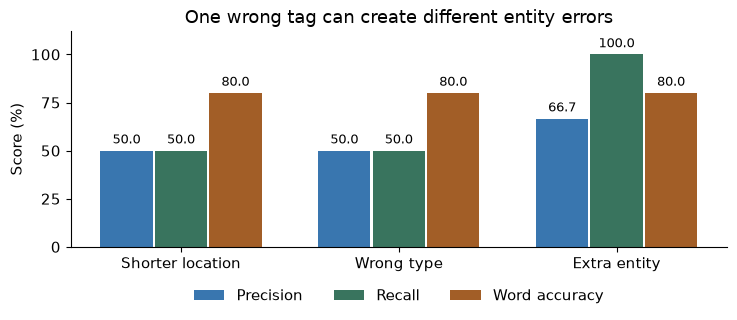

In [15]:
names = list(predictions)
reports = [span_metrics(gold_tags, predictions[name]) for name in names]
x = np.arange(len(names))
fig, ax = plt.subplots()
for offset, key, label, color in [
    (-.25, "precision", "Precision", "#3976AF"),
    (0, "recall", "Recall", "#39745E"),
    (.25, "word_accuracy", "Word accuracy", "#A25E27"),
]:
    values = [100*report[key] for report in reports]
    bars = ax.bar(x+offset, values, width=.24, label=label, color=color)
    ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=9)
ax.set_xticks(x, names)
ax.set(ylim=(0, 112), ylabel="Score (%)",
       title="One wrong tag can create different entity errors")
ax.set_yticks([0, 25, 50, 75, 100])
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.13), ncol=3, frameon=False)
fig.tight_layout()
plt.show()

## 10. Change the label mix (optional)

Take UPDATE as positive. Office 1 has 60 updates and 140 lookups; office 2 has
20 updates and 180 lookups. Multiply the number in each actual class by its
conditional flag rate: 90% for updates and 5% for lookups.

| Expected count | Office 1 | Office 2 |
| :-- | --: | --: |
| TP: updates flagged | 54 | 18 |
| FN: updates missed | 6 | 2 |
| FP: lookups flagged | 7 | 9 |
| TN: lookups not flagged | 133 | 171 |
| All flags | 61 | 27 |

Precision is $54/61\approx88.5\%$ in office 1 and $18/27\approx66.7\%$ in
office 2. Both have recall 90% and false-positive rate 5%. The second office has
fewer actual updates to find and more lookups that can trigger false alarms.
These are expected counts under the stipulated rates; finite samples can differ.

Writing $\pi$ for update prevalence, $r$ for recall and $f$ for the false-positive
rate gives population precision $r\pi/[r\pi+f(1-\pi)]$. Here $\pi$ is 0.3
or 0.1. The formula follows by dividing expected true flags by expected total
flags; it does not assume that conditional rates survive a real domain shift.

In [16]:
office_rows = []
for name, updates in [("Office 1", 60), ("Office 2", 20)]:
    lookups = 200-updates
    tp, fp = .90*updates, .05*lookups
    fn, tn = updates-tp, lookups-fp
    prevalence = updates/200
    precision = tp/(tp+fp)
    formula = .90*prevalence/(.90*prevalence + .05*(1-prevalence))
    np.testing.assert_allclose(precision, formula)
    office_rows.append((name, tp, fn, fp, tn, precision))
    print(f"{name}: TP={tp:.0f}, FN={fn:.0f}, FP={fp:.0f}, TN={tn:.0f}; "
          f"precision={precision:.3%}")
np.testing.assert_allclose([x[-1] for x in office_rows], [54/61, 18/27])

Office 1: TP=54, FN=6, FP=7, TN=133; precision=88.525%
Office 2: TP=18, FN=2, FP=9, TN=171; precision=66.667%


The figure isolates this change in prevalence. A useful additional check is
recall on indirectly phrased updates, such as *I moved last week*. Apply the same
annotation rule and decision threshold in both offices. Report how many such
updates each contains and the fraction flagged. Aggregate recall could stay the
same while performance on this important slice changes.

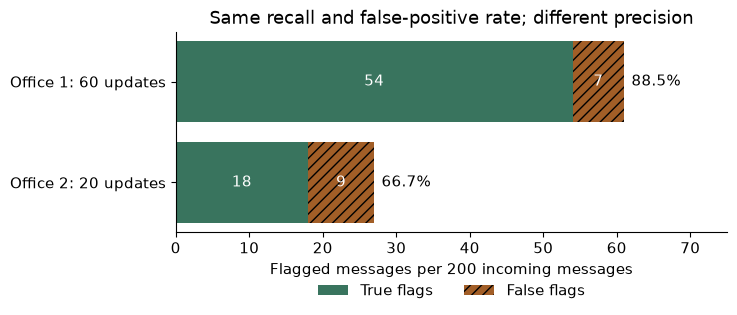

In [17]:
fig, ax = plt.subplots()
for y, (name, tp, fn, fp, tn, precision) in enumerate(office_rows):
    ax.barh(y, tp, color="#39745E", label="True flags" if y == 0 else None)
    ax.barh(y, fp, left=tp, color="#A25E27", hatch="///",
            label="False flags" if y == 0 else None)
    for center, value in [(tp/2, tp), (tp+fp/2, fp)]:
        ax.text(center, y, f"{value:.0f}", ha="center", va="center", color="white")
    ax.text(tp+fp+1, y, f"{precision:.1%}", va="center")
ax.set_yticks([0, 1], ["Office 1: 60 updates", "Office 2: 20 updates"])
ax.invert_yaxis()
ax.set(xlim=(0, 75), xlabel="Flagged messages per 200 incoming messages",
       title="Same recall and false-positive rate; different precision")
ax.legend(loc="upper center", bbox_to_anchor=(.5, -.19), ncol=2, frameon=False)
fig.tight_layout()
plt.show()

## 11. Plan an independent split (optional)

Imagine three offices using the same template, *Please send a copy of the address
on file*. A customer writes to Office A and follows up with Office B. A random
message split can put closely related requests on both sides. Choose the holdout
unit to match the generalization claim.

To test new customers, group by stable customer ID across all offices. Assign
every message and thread from a customer to one partition. Test customers must
be absent from both training and validation. Keep several offices represented if
the claim concerns new customers at familiar offices. Report customer and message
counts, label counts and the office mix in every partition.

To test a new office, hold out that office and select models on other offices.
For a test that also excludes familiar-customer shortcuts, remove from training
and validation all messages from customers appearing in the held-out office.
For example, if a customer used C and A, keep the C test messages and exclude
their A messages from fitting and selection. Record the exclusions. This is a
new-office comparison with a customer-disjoint constraint; office holdout alone
does not imply new customers. Repeat separately for other held-out offices if
the data supports it, and report each office rather than only a pooled result.

Audit templates as well as IDs. Compare normalized texts after replacing variable
slots such as names and addresses. Then flag likely paraphrases using word or
character overlap and semantic similarity, followed by manual checks. Common
topic does not imply identical intent: *confirm my new address* and *enter my new
address* may require different actions. Save the template-family IDs and the
rule used to create them.

If the claim includes unfamiliar wording, keep each prohibited template family
in one partition. Connecting records that share customer, thread or template
family forms groups that enforce all those constraints together. For an intact
held-out office, exclude linked customers or prohibited template families from
training and validation, then check again for overlap. Report how much data this
removes: strict constraints can connect much of the dataset and make the desired
independent comparison unsupported. If familiar templates are allowed by the
question, report that fact instead of presenting the test as unseen wording.

In the small audit, test records c1 and c2 come from Office C. Customer u1 also
has record a1 in Office A, so a1 is excluded. Records a2 and b1 remain for
training and validation. This checks the customer constraint; it does not
establish semantic independence of the complete dataset.

In [18]:
records = [
    {"id": "a1", "customer": "u1", "office": "A"},
    {"id": "a2", "customer": "u2", "office": "A"},
    {"id": "b1", "customer": "u3", "office": "B"},
    {"id": "c1", "customer": "u1", "office": "C"},
    {"id": "c2", "customer": "u4", "office": "C"},
]
test = [r for r in records if r["office"] == "C"]
candidates = [r for r in records if r["office"] != "C"]
test_customers = {r["customer"] for r in test}
fit_pool = [r for r in candidates if r["customer"] not in test_customers]
excluded = [r["id"] for r in candidates if r["customer"] in test_customers]
assert excluded == ["a1"]
assert not ({r["customer"] for r in fit_pool} & test_customers)
print("Test records:", [r["id"] for r in test])
print("Excluded familiar-customer records:", excluded)
print("Remaining pool for train/validation:", [r["id"] for r in fit_pool])

Test records: ['c1', 'c2']
Excluded familiar-customer records: ['a1']
Remaining pool for train/validation: ['a2', 'b1']


## 12. Design an entity error study (optional)

Evaluate both taggers on the same documents, preserving the original word
boundaries and gold location spans. Build the seen-name list from complete gold
locations in the task training split. Normalize by a declared rule, such as case
folding and collapsing spaces. A test gold name is seen if its full normalized
form is in that list. This measures exposure during task training: a pretrained
model may have encountered an otherwise unseen name elsewhere.

An exact match requires the same sentence, start, exclusive end and type.
For diagnosis, pair unmatched predictions with unmatched gold spans in the same
sentence using a fixed one-to-one overlap rule, such as greatest shared word
count with a deterministic tie break. An overlapping prediction with the correct
type but different boundaries is a boundary error. Identical boundaries with the
wrong type are a type error. Record both differences separately as a combined
error; unpaired gold spans are misses and unpaired predictions are false positives.
Diagnostic pairing never converts an error into an exact match. Use the same
declared IOB2 decoding or repair policy for both systems.

Assign paired errors to the slice of the complete gold name. If gold *Lake City*
is unseen and the tagger predicts only *Lake*, the boundary error belongs to the
unseen slice even if *Lake* alone was a training location. Assigning it by the
prediction's surface form would move the error into the wrong slice. Report
unpaired false positives separately because no gold name defines their slice.

For each slice, report support as the number of gold mentions, exact recall as
matched gold mentions divided by support, and boundary, type, combined-error and
miss counts. Report overall exact location precision with all predicted locations
in its denominator, including spurious and wrong-boundary ones. This avoids
inventing a slice precision denominator by silently dropping unpaired false
positives. For small slices, show raw numerators and denominators. Compare taggers
on paired documents and resample documents, rather than individual mentions,
if estimating uncertainty.

Finally record whether any word in each gold name splits into multiple subwords.
Compare recall and diagnostic counts for split and unsplit names within each seen
and unseen slice. Use one common tokenizer for this diagnostic or report each
model's fragmentation separately. Recover original word predictions with the
declared alignment policy before scoring. Inspect multi-piece errors to separate
alignment failures, boundary failures and type failures.

This example checks the slice-assignment pitfall. A full error study additionally
needs the document grouping, paired tagger outputs and support counts just described.

In [19]:
def normalize_name(name):
    return " ".join(name.casefold().split())

seen_names = {normalize_name(name) for name in ["Lake", "New Harbor"]}
words = ["Sam", "left", "Lake", "City"]
gold_location = (2, 4, "LOC")
short_prediction = (2, 3, "LOC")
gold_name = " ".join(words[gold_location[0]:gold_location[1]])
pred_name = " ".join(words[short_prediction[0]:short_prediction[1]])
gold_slice = "seen" if normalize_name(gold_name) in seen_names else "unseen"
wrong_slice = "seen" if normalize_name(pred_name) in seen_names else "unseen"
assert (gold_slice, wrong_slice) == ("unseen", "seen")
assert gold_location != short_prediction
print("Gold name:", gold_name, "->", gold_slice)
print("Predicted name:", pred_name, "->", wrong_slice, "if assigned incorrectly")
print("Correct diagnosis: boundary error in the unseen gold-name slice")

Gold name: Lake City -> unseen
Predicted name: Lake -> seen if assigned incorrectly
Correct diagnosis: boundary error in the unseen gold-name slice


The calculations show why the prediction unit matters: the same one-tag error
can have different entity-level consequences, and equal conditional error rates
can coexist with different precision. Preserve word alignment, sentence identity,
mask meanings and metric denominators from preparation through reporting.